# Exploración de arquitecturas de redes neuronales en el conjunto de datos Digits


Aqui exploraremos cómo diferentes arquitecturas de **redes neuronales** se comportan sobre el conjunto de datos **Digits**. 

El conjunto consta de $1797$ imágenes en escala de grises de dígitos manuscritos ($0$–$9$), cada una representada como una matriz de $8 \times 8$ píxeles.  

El flujo de trabajo será el siguiente:

1. Cargar y explorar el conjunto de datos.  
2. Preprocesar los datos (escalado y división en entrenamiento/test).  
3. Construir distintas arquitecturas de redes neuronales.  
4. Comparar el rendimiento mediante **curvas ROC** y el área bajo la curva (**AUC**).  




In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [4]:
digits = load_digits()

X = digits.data   # Valores de píxeles aplanados (64 características por imagen)
y = digits.target # Etiquetas: dígitos 0-9

df = pd.DataFrame(X, columns=[f'pixel_{i}' for i in range(X.shape[1])])
df['label'] = y

df.head()


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,label
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


## Estructura del dataset

Cada imagen se representa como un vector en $\mathbb{R}^{64}$, ya que tenemos $8 \times 8$ píxeles.  
Así, cada muestra corresponde a:

$$
\mathbf{x} = (x_1, x_2, \dots, x_{64}) \in \mathbb{R}^{64}
$$

con una etiqueta asociada $y \in \{0,1,2,\dots,9\}$.

Esto es análogo a un **vector de estado en Física**, donde las intensidades de los píxeles son componentes en un espacio de alta dimensión.  
La tarea de clasificación equivale a proyectar este estado sobre uno de los 10 posibles “autovalores” (los dígitos).


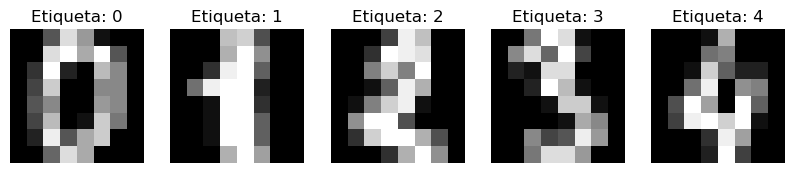

In [5]:
# Dibujar algunos ejemplos del dataset
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(f"Etiqueta: {digits.target[i]}")
    ax.axis("off")
plt.show()


In [6]:
# Preprocesameiento
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Escalado de datos: normalizamos a media 0 y varianza 1
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (1437, 64)
Test: (360, 64)


## Preprocesamiento: normalización y división de datos


La opción `stratify=y` garantiza que la proporción de cada dígito se mantenga constante en ambos conjuntos.  

Posteriormente normalizamos cada característica con:

$$
x'_j = \frac{x_j - \mu_j}{\sigma_j}
$$

donde $\mu_j$ y $\sigma_j$ son la media y la desviación estándar de la característica $j$.  

Este paso es esencial para redes neuronales, ya que:  
1. Reduce problemas numéricos en la retropropagación.  
2. Evita que algunas variables dominen sobre otras debido a su escala.  
3. Facilita la convergencia hacia mínimos durante el entrenamiento.


## Primera red neuronal

Definimos un perceptrón multicapa sencillo (MLP) con una capa oculta y salida softmax.  



In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Modelo: una capa oculta de 32 neuronas
model = keras.Sequential([
    layers.Input(shape=(64,)),              # 64 píxeles de entrada
    layers.Dense(32, activation="relu"),    # capa oculta
    layers.Dense(10, activation="softmax")  # salida para 10 clases
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,410 (9.41 KB)

 Trainable params: 2,410 (9.41 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
#entrenamiento
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)


Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1681 - loss: 2.4755 - val_accuracy: 0.4236 - val_loss: 1.8278
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 997us/step - accuracy: 0.4886 - loss: 1.7028 - val_accuracy: 0.6111 - val_loss: 1.3663
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 983us/step - accuracy: 0.6691 - loss: 1.2108 - val_accuracy: 0.7153 - val_loss: 1.0630
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 996us/step - accuracy: 0.7823 - loss: 0.9242 - val_accuracy: 0.7778 - val_loss: 0.8463
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8494 - loss: 0.7172 - val_accuracy: 0.8472 - val_loss: 0.6881
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 970us/step - accuracy: 0.8793 - loss: 0.5516 - val_accuracy: 0.8715 - val_loss: 0.5722
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 968us/step - accuracy: 0.9022 - loss: 0.4614 - val_accuracy: 0.8958 - val_loss: 0.4826
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 982us/step - accuracy: 0.9220 - loss: 0.3826 - val_accuracy: 0.8993

In [8]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.3f}")


Test Accuracy: 0.094


## Segunda arquitectura (MLP más profundo)

Probamos un MLP con dos capas ocultas (p.ej., 64 y 32 neuronas) y **Dropout** para reducir sobreajuste.  
Mantendremos el resto de hiperparámetros constantes para comparar con la arquitectura base en igualdad de condiciones.


In [9]:
# Segunda arquitectura: deep MLP con regularización
model_deep = keras.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_deep.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_deep.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Entrenamiento del deep modeloo
history_deep = model_deep.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

# Evaluación en test
test_loss_deep, test_acc_deep = model_deep.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy): {test_acc_deep:.3f}")


Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1964 - loss: 2.2321 - val_accuracy: 0.6354 - val_loss: 1.5864
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6299 - loss: 1.4736 - val_accuracy: 0.8090 - val_loss: 1.0092
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8326 - loss: 0.8877 - val_accuracy: 0.8889 - val_loss: 0.6157
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 997us/step - accuracy: 0.8830 - loss: 0.5293 - val_accuracy: 0.8993 - val_loss: 0.4281
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 997us/step - accuracy: 0.8975 - loss: 0.3929 - val_accuracy: 0.9306 - val_loss: 0.3145
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9217 - loss: 0.3032 - val_accuracy: 0.9306 - val_loss: 0.2520
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9478 - loss: 0.2189 - val_accuracy: 0.9444 - val_loss: 0.2187
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9509 - loss: 0.1889 - val_accuracy: 0.9444 - val_l

## Tercera arquitectura (red convolucional ligera)

A diferencia de los MLP, las **redes convolucionales (CNNs)** están diseñadas para explotar la estructura espacial de los datos.  
En lugar de tratar cada píxel como una entrada independiente, la convolución utiliza **filtros locales** que barren la imagen y capturan patrones como bordes, curvas o regiones contrastadas.  

Cada capa convolucional genera un conjunto de **mapas de características** que representan distintos aspectos de la imagen.  
El *pooling* reduce la dimensionalidad preservando la información relevante, mientras que las capas densas finales se encargan de la clasificación.  

En este caso implementamos una CNN mínima con:
- Una capa convolucional de 16 filtros $3 \times 3$ con activación ReLU.  
- Una capa de *max pooling* $2 \times 2$ para reducción espacial.  
- Una capa densa intermedia y una salida softmax para clasificar en 10 dígitos.


In [16]:
# Reestructuramos datos a formato imagen: (n_muestras, 8, 8, 1)
X_train_img = X_train.reshape(-1, 8, 8, 1)
X_test_img  = X_test.reshape(-1, 8, 8, 1)

# CNN ligera
model_cnn = keras.Sequential([
    layers.Conv2D(16, (3,3), activation="relu", input_shape=(8,8,1)),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.summary()


C:\Users\pc\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 6, 6, 16)            │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 3, 3, 16)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 144)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 32)                  │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,130 (20.04 KB)

 Trainable params: 5,130 (20.04 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Entrenamiento de la CNN
history_cnn = model_cnn.fit(
    X_train_img, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

test_loss_cnn, test_acc_cnn = model_cnn.evaluate(X_test_img, y_test, verbose=0)
print(f"Test Accuracy: {test_acc_cnn:.3f}")


Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1885 - loss: 2.2602 - val_accuracy: 0.4132 - val_loss: 1.8260
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5780 - loss: 1.6032 - val_accuracy: 0.7639 - val_loss: 1.1593
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8492 - loss: 0.9396 - val_accuracy: 0.8472 - val_loss: 0.6723
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9221 - loss: 0.5002 - val_accuracy: 0.9062 - val_loss: 0.4348
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9512 - loss: 0.3239 - val_accuracy: 0.9167 - val_loss: 0.3364
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9589 - loss: 0.2601 - val_accuracy: 0.9375 - val_loss: 0.2888
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9587 - loss: 0.2008 - val_accuracy: 0.9410 - val_loss: 0.2513
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9739 - loss: 0.1420 - val_accuracy: 0.9375 - val_loss:

## Curvas ROC y AUC

La métrica *accuracy* resume el rendimiento de un modelo en un único número, pero no informa sobre su comportamiento al variar el umbral de decisión.  
Las **curvas ROC** permiten analizar la relación entre la tasa de verdaderos positivos (TPR) y la tasa de falsos positivos (FPR) para distintos umbrales.  

En problemas multiclase se utiliza el esquema **One-vs-Rest**: para cada clase $k$ se calcula una curva ROC considerando esa clase como positiva y las demás como negativas.  
A partir de estas curvas se definen dos promedios relevantes:

- **Micro-average**: computa métricas globales considerando todos los ejemplos.  
- **Macro-average**: promedia las métricas de cada clase, otorgando igual peso a todas.  

El área bajo la curva (**AUC**) cuantifica el rendimiento global del clasificador: cuanto más próximo a 1, mejor discriminación.


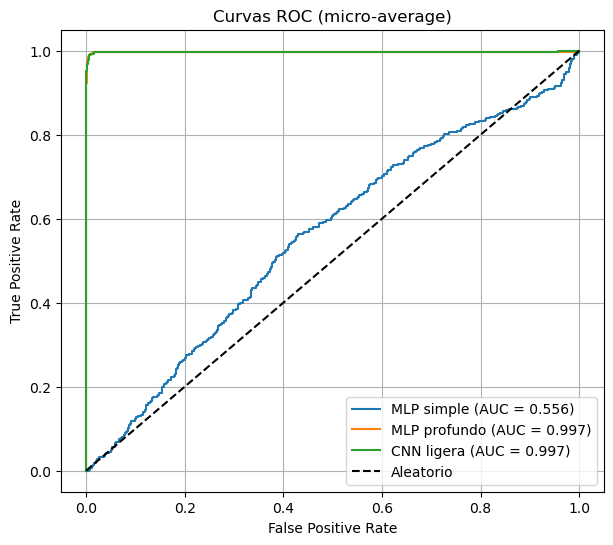

AUC macro MLP simple:   0.541
AUC macro MLP profundo: 0.997
AUC macro CNN ligera:   0.997


In [13]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Número de clases
n_classes = 10
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

# Probabilidades de cada modelo
y_proba_base = model.predict(X_test, verbose=0)
y_proba_deep = model_deep.predict(X_test, verbose=0)
y_proba_cnn  = model_cnn.predict(X_test_img, verbose=0)

def compute_macro_micro_auc(y_true_bin, y_proba):
    fpr, tpr, roc_auc = dict(), dict(), dict()
    for k in range(n_classes):
        fpr[k], tpr[k], _ = roc_curve(y_true_bin[:, k], y_proba[:, k])
        roc_auc[k] = auc(fpr[k], tpr[k])
    # micro-average
    fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_proba.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    # macro-average
    roc_auc["macro"] = np.mean([roc_auc[k] for k in range(n_classes)])
    return fpr, tpr, roc_auc

# Calcular AUC para cada modelo
fpr_base, tpr_base, auc_base = compute_macro_micro_auc(y_test_bin, y_proba_base)
fpr_deep, tpr_deep, auc_deep = compute_macro_micro_auc(y_test_bin, y_proba_deep)
fpr_cnn,  tpr_cnn,  auc_cnn  = compute_macro_micro_auc(y_test_bin, y_proba_cnn)

# Graficar curvas ROC (micro-average para claridad)
plt.figure(figsize=(7,6))
plt.plot(fpr_base["micro"], tpr_base["micro"],
         label=f"MLP simple (AUC = {auc_base['micro']:.3f})")
plt.plot(fpr_deep["micro"], tpr_deep["micro"],
         label=f"MLP profundo (AUC = {auc_deep['micro']:.3f})")
plt.plot(fpr_cnn["micro"], tpr_cnn["micro"],
         label=f"CNN ligera (AUC = {auc_cnn['micro']:.3f})")

plt.plot([0,1], [0,1], "k--", label="Aleatorio")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curvas ROC (micro-average)")
plt.legend()
plt.grid(True)
plt.show()

print(f"AUC macro MLP simple:   {auc_base['macro']:.3f}")
print(f"AUC macro MLP profundo: {auc_deep['macro']:.3f}")
print(f"AUC macro CNN ligera:   {auc_cnn['macro']:.3f}")


## Curvas de aprendizaje (train y validación)

Comparamos la dinámica de entrenamiento de las tres arquitecturas mediante las curvas de **accuracy** en entrenamiento y validación. Esto permite evaluar estabilidad, convergencia y posible sobreajuste.


In [14]:
def plot_learning_curves(hist, label_prefix):
    acc = hist.history.get("accuracy", [])
    val_acc = hist.history.get("val_accuracy", [])
    return acc, val_acc

acc_base, val_acc_base   = plot_learning_curves(history,       "MLP simple")
acc_deep, val_acc_deep   = plot_learning_curves(history_deep,  "MLP profundo")
acc_cnn,  val_acc_cnn    = plot_learning_curves(history_cnn,   "CNN ligera")

epochs_base = range(1, len(acc_base) + 1)
epochs_deep = range(1, len(acc_deep) + 1)
epochs_cnn  = range(1, len(acc_cnn) + 1)

# Accuracy de validación (comparada)
plt.figure(figsize=(7,5))
plt.plot(epochs_base, val_acc_base, label="MLP simple (val)")
plt.plot(epochs_deep, val_acc_deep, label="MLP profundo (val)")
plt.plot(epochs_cnn,  val_acc_cnn,  label="CNN ligera (val)")
plt.xlabel("Época")
plt.ylabel("Accuracy de validación")
plt.title("Curvas de validación")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy de entrenamiento (comparada)
plt.figure(figsize=(7,5))
plt.plot(epochs_base, acc_base, label="MLP simple (train)")
plt.plot(epochs_deep, acc_deep, label="MLP profundo (train)")
plt.plot(epochs_cnn,  acc_cnn,  label="CNN ligera (train)")
plt.xlabel("Época")
plt.ylabel("Accuracy de entrenamiento")
plt.title("Curvas de entrenamiento")
plt.legend()
plt.grid(True)
plt.show()


NameError: name 'history' is not defined

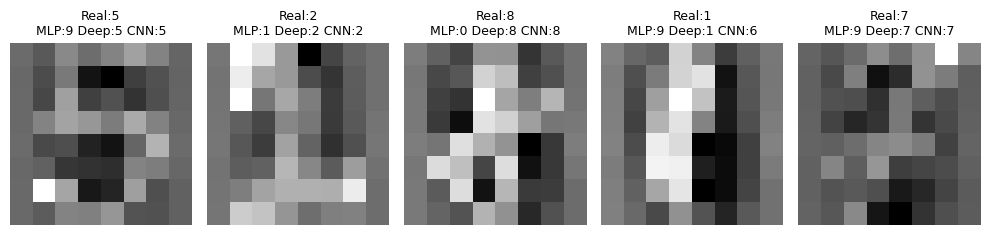

In [15]:
#Predicción de un dígito del test
# Número de imágenes a mostrar
n = 5  

fig, axes = plt.subplots(1, 5, figsize=(10, 5))  

for i, ax in enumerate(axes.flat):
    idx = i  # índice de la imagen en el test set
    
    # Imagen en formato 8x8
    img = X_test[idx].reshape(8, 8)
    
    # Formatos para los modelos
    x_input_mlp = X_test[idx].reshape(1, -1)
    x_input_cnn = X_test_img[idx].reshape(1, 8, 8, 1)
    
    # Predicciones de cada modelo
    pred_base = np.argmax(model.predict(x_input_mlp, verbose=0))
    pred_deep = np.argmax(model_deep.predict(x_input_mlp, verbose=0))
    pred_cnn  = np.argmax(model_cnn.predict(x_input_cnn, verbose=0))
    
    # Mostrar imagen
    ax.imshow(img, cmap="gray", interpolation="nearest")
    ax.axis("off")
    
    # Título con etiqueta real y predicciones
    ax.set_title(
        f"Real:{y_test[idx]}\nMLP:{pred_base} Deep:{pred_deep} CNN:{pred_cnn}",
        fontsize=9
    )

plt.tight_layout()
plt.show()


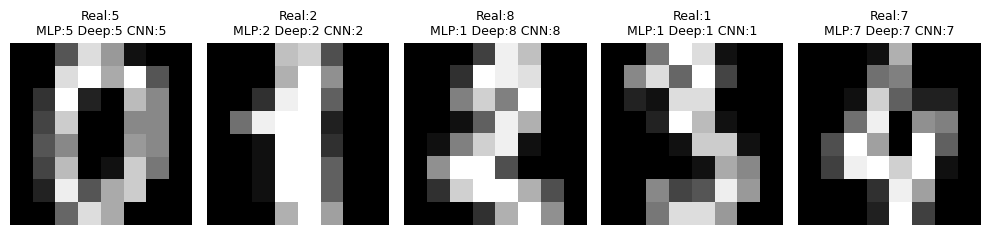

In [26]:
# Mostrar varias imágenes del conjunto de test con etiquetas y predicciones
n = 5
fig, axes = plt.subplots(1, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    idx = i  # índice en el conjunto de test

    # Imagen ORIGINAL (sin escalar)
    img_original = digits.images[X_test.index[idx]] if isinstance(X_test, pd.DataFrame) else digits.images[idx]

    # Formatos para los modelos
    x_input_mlp = X_test[idx].reshape(1, -1)
    x_input_cnn = X_test_img[idx].reshape(1, 8, 8, 1)

    # Predicciones
    pred_base = np.argmax(model.predict(x_input_mlp, verbose=0))
    pred_deep = np.argmax(model_deep.predict(x_input_mlp, verbose=0))
    pred_cnn  = np.argmax(model_cnn.predict(x_input_cnn, verbose=0))

    # Mostrar la imagen
    ax.imshow(img_original, cmap="gray", interpolation="nearest")
    ax.axis("off")

    # Título
    ax.set_title(
        f"Real:{y_test[idx]}\nMLP:{pred_base} Deep:{pred_deep} CNN:{pred_cnn}",
        fontsize=9
    )

plt.tight_layout()
plt.show()
